# Taller 1 - Gestión de Datos
## Grupo: Juan Camilo Guerrero, Maria Camila Rincón, Luis Alberto Banda, Juan Pablo Marin y Gabriel Camilo Velasquez
## 1. Datos

**Objetivo del análisis:** preparar y cargar las tablas del taller de forma reproducible, para poder explorarlas en las secciones siguientes.

**Descripción del dataset:** se encuentra en la carpeta `Data` del workspace y consta de tres archivos:

| Archivo | Formato | Contenido |
|---|---|---|
| `countries.csv` | CSV | Tabla de países con su código, latitud, longitud y nombre. |
| `diabetes.csv` | CSV | Tabla de mediciones clínicas de pacientes y un indicador de diabetes (`Outcome`). |
| `Currencies.json` | JSON | Tabla de monedas por país, con sus códigos y nombres. |

### 1.1 Librerías
Importamos las librerías que usaremos durante todo el taller.

In [51]:
# Librerías del taller
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### 1.2 Archivos disponibles
Listamos los archivos de `Data` con su tamaño. Si alguno pesa menos de 1 KB, probablemente es un puntero de Git LFS (no el dato real) y detenemos la ejecución.

In [52]:
# Ubicamos la carpeta Data (el notebook vive en work/, Data está un nivel arriba)
RUTAS_POSIBLES = [Path("../Data"), Path("Data")]
DATA_DIR = next((r for r in RUTAS_POSIBLES if r.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta 'Data'. Si usas Docker, recuerda que solo "
        "./work está montada en el contenedor: monta también ./Data."
    )

# Listamos cada archivo (csv y json) con su tamaño
archivos = sorted(list(DATA_DIR.glob("*.csv")) + list(DATA_DIR.glob("*.json")))
for archivo in archivos:
    print(f"{archivo.name:<20} {archivo.stat().st_size / 1024:>8.1f} KB")

# Un archivo < 1 KB es casi seguro un puntero de Git LFS
pequenos = [a.name for a in archivos if a.stat().st_size < 1024]
if pequenos:
    raise SystemExit(
        f"Detenido: {pequenos} pesan menos de 1 KB (puntero de Git LFS). "
        "Ejecuta 'git lfs pull' para descargar los datos reales."
    )

Currencies.json          44.2 KB
countries.csv             8.5 KB
diabetes.csv             23.3 KB


### 1.3 Carga de tablas
Cargamos `countries`, `Currencies` y `diabetes`. Convertimos a fecha las columnas cuyo nombre contenga `date` o `timestamp`, o termine en `_at`, e imprimimos el `shape` de cada tabla.

In [53]:
def es_columna_fecha(nombre):
    n = str(nombre).lower()
    return "date" in n or "timestamp" in n or n.endswith("_at")

tablas = {
    "countries": pd.read_csv(DATA_DIR / "countries.csv"),
    "Currencies": pd.read_json(DATA_DIR / "Currencies.json"),
    "diabetes": pd.read_csv(DATA_DIR / "diabetes.csv"),
}

for nombre, df in tablas.items():
    cols_fecha = [c for c in df.columns if es_columna_fecha(c)]
    for c in cols_fecha:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    print(f"{nombre:<11} shape={df.shape}  columnas de fecha convertidas: {cols_fecha or 'ninguna'}")

countries, Currencies, diabetes = tablas["countries"], tablas["Currencies"], tablas["diabetes"]

countries   shape=(245, 4)  columnas de fecha convertidas: ninguna
Currencies  shape=(254, 5)  columnas de fecha convertidas: ninguna
diabetes    shape=(768, 9)  columnas de fecha convertidas: ninguna


## 2. Perfilamiento

Resumimos cada atributo de las tablas cargadas: tipo de almacenamiento, tipo conceptual, nulos, valores distintos y estadísticos básicos.

> **Importante:** la columna `tipo_conceptual_sugerido` sale de reglas simples (dtype, número de valores distintos y nombre de la columna). Es solo una **sugerencia**: el analista debe validarla.

In [5]:
def tipo_conceptual(serie):
    """Sugiere el tipo conceptual de una columna con reglas simples (validar manualmente)."""
    n = serie.dropna()
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "fecha"
    if isinstance(serie.dtype, pd.CategoricalDtype) and serie.dtype.ordered:
        return "ordinal"
    # Identificador: todos los valores distintos (no flotantes) o nombre típico de código/id
    nombre = str(serie.name).lower()
    es_id_por_nombre = nombre == "id" or nombre.endswith("_id") or "code" in nombre
    if not pd.api.types.is_float_dtype(serie) and len(n) > 0 and (n.nunique() == len(n) or es_id_por_nombre):
        return "identificador"
    if pd.api.types.is_bool_dtype(serie) or not pd.api.types.is_numeric_dtype(serie):
        return "nominal"
    if n.nunique() <= 2:
        return "nominal"  # variable binaria
    return "discreta" if pd.api.types.is_integer_dtype(serie) else "continua"


def perfil(df, tabla):
    """Devuelve una fila de perfilamiento por cada atributo de df."""
    filas = []
    for col in df.columns:
        s = df[col]
        es_num = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        es_fecha = pd.api.types.is_datetime64_any_dtype(s)
        moda = s.mode(dropna=True)
        filas.append({
            "atributo": col,
            "tabla": tabla,
            "dtype": str(s.dtype),
            "tipo_conceptual_sugerido": tipo_conceptual(s),
            "nulos": int(s.isna().sum()),
            "%_nulos": round(s.isna().mean() * 100, 2),
            "distintos": int(s.nunique(dropna=True)),
            "media": s.mean() if es_num else np.nan,
            "desv_est": s.std() if es_num else np.nan,
            "moda": moda.iloc[0] if len(moda) else np.nan,
            "minimo": s.min() if (es_num or es_fecha) else np.nan,
            "maximo": s.max() if (es_num or es_fecha) else np.nan,
        })
    return pd.DataFrame(filas)


# Aplicamos la función a todas las tablas cargadas y concatenamos
perfiles = pd.concat([perfil(df, nombre) for nombre, df in tablas.items()], ignore_index=True)
perfiles = perfiles.sort_values(["%_nulos", "tabla"], ascending=[False, True], ignore_index=True)
perfiles

,atributo,tabla,dtype,tipo_conceptual_sugerido,nulos,%_nulos,distintos,media,desv_est,moda,minimo,maximo
0,country,countries,object,identificador,1,0.41,244,NaN,NaN,AD,NaN,NaN
1,latitude,countries,float64,continua,1,0.41,244,16.253109,27.031206,-75.250973,-75.250973,77.553604
2,longitude,countries,float64,continua,1,0.41,244,13.294814,73.976477,-177.156097,-177.156097,179.414413
3,Country,Currencies,object,identificador,0,0.00,254,NaN,NaN,ALand Islands,NaN,NaN
4,Country code (Alpha-2),Currencies,object,identificador,0,0.00,254,NaN,NaN,AC,NaN,NaN
5,Country code (Alpha-3),Currencies,object,identificador,0,0.00,253,NaN,NaN,,NaN,NaN
6,Currency,Currencies,object,nominal,0,0.00,155,NaN,NaN,Euro,NaN,NaN
7,Currency code,Currencies,object,identificador,0,0.00,155,NaN,NaN,EUR,NaN,NaN
8,name,countries,object,identificador,0,0.00,245,NaN,NaN,Afghanistan,NaN,NaN
9,Pregnancies,diabetes,int64,discreta,0,0.00,17,3.845052,3.369578,1.0,0.000000,17.000000


## 2.1 Ejercicio 1

El perfilamiento mostró un nulo en `country`, `latitude` y `longitude` de la tabla `countries`. Primero ubicamos las filas con nulos y luego las cruzamos con `Currencies` para identificar a qué países corresponden.

In [8]:
# Filas de countries con algún nulo en country, latitude o longitude
cols_revisar = ["country", "latitude", "longitude"]
filas_nulas = countries[countries[cols_revisar].isna().any(axis=1)].copy()
filas_nulas["columnas_nulas"] = filas_nulas[cols_revisar].apply(
    lambda f: ", ".join(f.index[f.isna()]), axis=1
)
filas_nulas

,country,latitude,longitude,name,columnas_nulas
156,NaN,-22.95764,18.49041,Namibia,country
226,UM,NaN,NaN,U.S. Minor Outlying Islands,"latitude, longitude"


### Cruce con `Currencies`
Llave principal: `countries.country` = `Currencies."Country code (Alpha-2)"`. Si el código es nulo, el cruce por código no es posible; en ese caso usamos como llave alternativa el nombre (`countries.name` = `Currencies.Country`).

In [9]:
alpha2 = "Country code (Alpha-2)"

# 1) Cruce por código cuando el código existe
por_codigo = (
    filas_nulas.dropna(subset=["country"])
    .merge(Currencies, left_on="country", right_on=alpha2, how="left")
    .assign(llave_usada="código (Alpha-2)")
)

# 2) Cruce por nombre cuando el código es nulo
por_nombre = (
    filas_nulas[filas_nulas["country"].isna()]
    .merge(Currencies, left_on="name", right_on="Country", how="left")
    .assign(llave_usada="nombre")
)

cruce_nulos = pd.concat([por_codigo, por_nombre], ignore_index=True)
cruce_nulos[["name", "columnas_nulas", "llave_usada", "Country", alpha2,
             "Country code (Alpha-3)", "Currency", "Currency code"]]

,name,columnas_nulas,llave_usada,Country,Country code (Alpha-2),Country code (Alpha-3),Currency,Currency code
0,U.S. Minor Outlying Islands,"latitude, longitude",código (Alpha-2),U.S. Outlying Islands,UM,UMI,US Dollar,USD
1,Namibia,country,nombre,Namibia,NA,NAM,Namibian Dollar,NAD


### Preguntas 4, 5 y 6: llave de unión, cruce y comparación con el nombre

**4. Llave identificada:** `countries.country` = `Currencies."Country code (Alpha-2)"`, es decir, el código ISO 3166-1 de dos letras. (`Currencies` también trae el código Alpha-3, pero `countries` no lo tiene, así que Alpha-2 es la llave común.)

**¿Por qué es mejor el código ISO que el nombre?**
- **Es un estándar:** un código identifica un solo país y es el mismo en todas las fuentes. El nombre depende de cómo cada fuente lo escribe.
- **El nombre varía** entre tablas: corchetes (`Congo [DRC]`), acentos y codificación (`Côte d'Ivoire`), nombres alternativos (`Myanmar [Burma]`, `Macedonia [FYROM]`), etc. Un cruce exacto por texto pierde esas filas.
- **Es corto y no tiene ambigüedad** de mayúsculas, espacios, idioma o signos.

**5. Unión:** `pd.merge(..., how="outer", indicator=True)` por la llave ISO. Reportamos cuántos registros quedaron en ambas tablas, solo en `countries` y solo en `Currencies`, y listamos los que no cruzaron. Al final comparamos con el cruce por nombre para respaldar la respuesta a la pregunta 4.

**6. Unión usando el nombre como llave:** repetimos el `merge` con `countries.name` = `Currencies.Country` y comparamos cuántos registros cruzan frente al cruce por código ISO. La diferencia son los registros que se pierden.

**Causa (dos ejemplos):** el mismo país está escrito distinto en cada tabla, por lo que la comparación exacta de texto falla aunque el código ISO sea el mismo.
- **Formato del nombre:** `Myanmar [Burma]` (countries) frente a `Myanmar` (Currencies), ambos con el código `MM`.
- **Codificación de caracteres:** `Côte d'Ivoire` (countries) frente a `C�te d�Ivoire` (Currencies), ambos con el código `CI`. El carácter acentuado se dañó en `Currencies`.

El código de la celda siguiente cuantifica la pérdida y lista los países afectados.

In [10]:
alpha2 = "Country code (Alpha-2)"
etiquetas = {"both": "en ambas tablas", "left_only": "solo en countries", "right_only": "solo en Currencies"}

# Pregunta 4: ¿la llave identifica de forma única a cada país?
print("country (countries) único:", countries["country"].dropna().is_unique)
print("Alpha-2 (Currencies) único:", Currencies[alpha2].is_unique)

# Punto 5: unión outer por código ISO
cruce = countries.merge(Currencies, left_on="country", right_on=alpha2, how="outer", indicator=True)
cruce["_merge"] = cruce["_merge"].astype(str).map(etiquetas)

print("\nRegistros por resultado del cruce (llave: código ISO):")
display(cruce["_merge"].value_counts().rename("registros").to_frame())

# Registros que no cruzaron
print("Registros que NO cruzaron:")
no_cruzan = cruce[cruce["_merge"] != "en ambas tablas"]
display(no_cruzan[["_merge", "country", "name", alpha2, "Country"]]
        .sort_values(["_merge", "name", "Country"], ignore_index=True))

# Respaldo de la pregunta 4: mismo cruce usando el nombre como llave
cruce_nombre = countries.merge(Currencies, left_on="name", right_on="Country", how="outer", indicator=True)
cruce_nombre["_merge"] = cruce_nombre["_merge"].astype(str).map(etiquetas)
comparacion = pd.concat(
    {"código ISO": cruce["_merge"].value_counts(), "nombre": cruce_nombre["_merge"].value_counts()}, axis=1
)
print("Comparación de llaves (número de registros):")
display(comparacion)

# Punto 6: registros que se pierden al usar el nombre como llave
cruzan_codigo = comparacion.loc["en ambas tablas", "código ISO"]
cruzan_nombre = comparacion.loc["en ambas tablas", "nombre"]
print(f"Cruzan por código ISO: {cruzan_codigo} | por nombre: {cruzan_nombre} | se pierden: {cruzan_codigo - cruzan_nombre}")

# Causa: países con el mismo código ISO pero nombre escrito distinto en cada tabla
mismo_codigo = countries.merge(Currencies, left_on="country", right_on=alpha2)
nombre_distinto = mismo_codigo[mismo_codigo["name"] != mismo_codigo["Country"]]
print(f"Países con el mismo código pero nombre distinto: {len(nombre_distinto)}")
display(nombre_distinto[["country", "name", "Country"]].reset_index(drop=True))


country (countries) único: True
Alpha-2 (Currencies) único: True

Registros por resultado del cruce (llave: código ISO):


,registros
_merge,
en ambas tablas,243
solo en Currencies,11
solo en countries,2


Registros que NO cruzaron:


,_merge,country,name,Country code (Alpha-2),Country
0,solo en Currencies,NaN,NaN,AX,ALand Islands
1,solo en Currencies,NaN,NaN,AC,Ascension Island
2,solo en Currencies,NaN,NaN,IC,Canary Islands
3,solo en Currencies,NaN,NaN,CW,Curacao
4,solo en Currencies,NaN,NaN,NA,Namibia
5,solo en Currencies,NaN,NaN,BL,Saint BarthLemy
6,solo en Currencies,NaN,NaN,MF,Saint Martin (French Part)
7,solo en Currencies,NaN,NaN,CS,Serbia and Montenegro
8,solo en Currencies,NaN,NaN,SX,Sint Maarten (Dutch Part)
9,solo en Currencies,NaN,NaN,SS,South Sudan


Comparación de llaves (número de registros):


,código ISO,nombre
_merge,,
en ambas tablas,243,229
solo en Currencies,11,25
solo en countries,2,16


Cruzan por código ISO: 243 | por nombre: 229 | se pierden: 14
Países con el mismo código pero nombre distinto: 15


,country,name,Country
0,CC,Cocos [Keeling] Islands,Clipperton Island
1,CD,Congo [DRC],Congo - Kinshasa
2,CG,Congo [Republic],Congo - Brazzaville
3,CI,Côte d'Ivoire,C�te d�Ivoire
4,FK,Falkland Islands [Islas Malvinas],Falkland Islands
5,IM,Isle of Man,Isle Of Man
6,MK,Macedonia [FYROM],Macedonia
7,MM,Myanmar [Burma],Myanmar
8,PN,Pitcairn Islands,Pitcairn
9,PS,Palestinian Territories,Palestine


### Puntos 7 y 8: guardado de la unión y reportes

**7. Guardado:** exportamos con `to_csv(index=False)` el resultado de la unión por código ISO (el `merge` *outer* del punto 5, que incluye la columna `_merge` con el origen de cada fila). El archivo queda junto al notebook, en `work/Countries_Currencies.csv`.

**8. Reportes:**
- **Tendencia central:** media, mediana, desviación estándar, mínimo, máximo y cuartiles (Q1 y Q3) de `latitude` y `longitude`, calculados sobre `countries`. La fila `n` indica cuántos valores no nulos se usaron.
- **ydata-profiling:** reporte HTML de la unión, guardado en `work/Countries_Currencies_profiling.html`. Ábrelo en el navegador.

In [11]:
# Punto 7: guardar la unión por código ISO (cruce de la pregunta 5) en CSV
ARCHIVO_CSV = Path("Countries_Currencies.csv")
cruce.to_csv(ARCHIVO_CSV, index=False)
print(f"Guardado: {ARCHIVO_CSV} ({ARCHIVO_CSV.stat().st_size / 1024:.1f} KB, {cruce.shape[0]} filas x {cruce.shape[1]} columnas)")

# Punto 8a: tendencia central y dispersión de latitud y longitud (tabla countries)
tendencia = (
    countries[["latitude", "longitude"]]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .rename(index={"count": "n (sin nulos)", "mean": "media", "std": "desv_est", "min": "mínimo",
                   "25%": "Q1 (25%)", "50%": "mediana (50%)", "75%": "Q3 (75%)", "max": "máximo"})
)
display(tendencia.round(4))

# Punto 8b: reporte de ydata-profiling en HTML (sobre la unión guardada)
from ydata_profiling import ProfileReport

ARCHIVO_HTML = Path("Countries_Currencies_profiling.html")
reporte = ProfileReport(cruce, title="Countries_Currencies", minimal=False)
reporte.to_file(ARCHIVO_HTML)
print(f"Reporte HTML generado: {ARCHIVO_HTML} ({ARCHIVO_HTML.stat().st_size / 1024:.0f} KB)")

Guardado: Countries_Currencies.csv (21.3 KB, 256 filas x 10 columnas)


,latitude,longitude
n (sin nulos),244.0000,244.0000
media,16.2531,13.2948
desv_est,27.0312,73.9765
mínimo,-75.2510,-177.1561
Q1 (25%),-0.3017,-38.0920
mediana (50%),16.8692,18.1821
Q3 (75%),38.9652,49.0467
máximo,77.5536,179.4144


/tmp/ipykernel_110/1616183094.py:16: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 530.21it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte HTML generado: Countries_Currencies_profiling.html (3487 KB)


## 2.2 Ejercicio 2

Trabajamos con el dataset del Titanic (12 columnas), cargado directamente desde su URL en GitHub. Cada punto tiene su propio bloque de código.

### Punto 1: carga del dataset
Cargamos el CSV desde la URL *raw* y mostramos las 10 primeras filas.

In [6]:
URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(URL_TITANIC)

print(f"Titanic: {titanic.shape[0]} filas x {titanic.shape[1]} columnas")
titanic.head(10)

Titanic: 891 filas x 12 columnas


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Punto 2: tabla resumen de atributos
Construimos la tabla resumen con la función `perfil()` de la sección 2: tipo de almacenamiento (`dtype`), tipo conceptual, número y % de nulos, valores distintos y, cuando aplica, media, desviación estándar, moda, mínimo y máximo.

`tipo_conceptual_sugerido` sale de reglas automáticas (dtype, valores distintos y nombre de la columna). En `tipo_conceptual_validado` dejamos el criterio del analista: `Pclass` pasa a **ordinal** porque sus categorías tienen orden (1.ª, 2.ª y 3.ª clase), algo que las reglas automáticas no detectan.

In [7]:
# Reutilizamos la función perfil() de la sección 2 (misma tabla resumen de atributos)
resumen_titanic = perfil(titanic, "titanic").drop(columns="tabla")

# Validación del analista: Pclass tiene un orden natural (1.ª > 2.ª > 3.ª clase), por lo que es ordinal.
# El resto de los tipos sugeridos se mantiene.
ajustes = {"Pclass": "ordinal"}
resumen_titanic.insert(
    resumen_titanic.columns.get_loc("tipo_conceptual_sugerido") + 1,
    "tipo_conceptual_validado",
    resumen_titanic["atributo"].map(ajustes).fillna(resumen_titanic["tipo_conceptual_sugerido"]),
)
resumen_titanic

,atributo,dtype,tipo_conceptual_sugerido,tipo_conceptual_validado,nulos,%_nulos,distintos,media,desv_est,moda,minimo,maximo
0,PassengerId,int64,identificador,identificador,0,0.00,891,446.000000,257.353842,1,1.00,891.0000
1,Survived,int64,nominal,nominal,0,0.00,2,0.383838,0.486592,0,0.00,1.0000
2,Pclass,int64,discreta,ordinal,0,0.00,3,2.308642,0.836071,3,1.00,3.0000
3,Name,object,identificador,identificador,0,0.00,891,NaN,NaN,"Abbing, Mr. Anthony",NaN,NaN
4,Sex,object,nominal,nominal,0,0.00,2,NaN,NaN,male,NaN,NaN
5,Age,float64,continua,continua,177,19.87,88,29.699118,14.526497,24.0,0.42,80.0000
6,SibSp,int64,discreta,discreta,0,0.00,7,0.523008,1.102743,0,0.00,8.0000
7,Parch,int64,discreta,discreta,0,0.00,7,0.381594,0.806057,0,0.00,6.0000
8,Ticket,object,nominal,nominal,0,0.00,681,NaN,NaN,1601,NaN,NaN
9,Fare,float64,continua,continua,0,0.00,248,32.204208,49.693429,8.05,0.00,512.3292


### Punto 3: justificación del tipo conceptual
Justificamos el tipo de `PassengerId`, `Pclass`, `Survived` y `SibSp` y comparamos con su tipo de almacenamiento (`dtype`).

| Columna | Tipo conceptual | Justificación | ¿El `dtype` corresponde? |
|---|---|---|---|
| `PassengerId` | **Identificador** | Un valor único por pasajero (todos distintos). Solo sirve para nombrar a cada registro; sumarlo o promediarlo no tiene sentido. | **No.** Está como `int64` (numérico), pero no se usa para calcular: debería tratarse como texto. |
| `Pclass` | **Ordinal** | Solo tiene 3 categorías con orden natural (1.ª > 2.ª > 3.ª clase), pero la distancia entre ellas no es medible. | **No.** Está como `int64`, que sugiere una variable numérica (el promedio 2,31 no tiene interpretación). Debería ser una categoría ordenada. |
| `Survived` | **Nominal** (binaria) | Dos categorías sin orden: 0 = no sobrevivió, 1 = sobrevivió. | **No.** Está como `int64`; lo adecuado es un booleano o una categoría. |
| `SibSp` | **Discreta** | Es un conteo (número de hermanos/cónyuges a bordo): valores enteros, con orden y distancia con sentido. | **Sí.** `int64` es adecuado para un conteo. |

**Conclusión:** `PassengerId`, `Pclass` y `Survived` están guardados como enteros aunque conceptualmente no son numéricos; solo `SibSp` tiene un `dtype` coherente con su tipo conceptual. La tabla siguiente lo respalda con los datos.

In [30]:
cols = ["PassengerId", "Pclass", "Survived", "SibSp"]

# Evidencia de los datos: valores distintos, unicidad y rango de cada columna
evidencia = pd.DataFrame({
    "dtype": titanic[cols].dtypes.astype(str),
    "distintos": titanic[cols].nunique(),
    "todos_unicos": [titanic[c].is_unique for c in cols],
    "minimo": titanic[cols].min(),
    "maximo": titanic[cols].max(),
    "valores (si hay <= 10)": [
        sorted(titanic[c].unique().tolist()) if titanic[c].nunique() <= 10 else "-" for c in cols
    ],
})

# Tipo conceptual validado en el punto 2 y tipo de almacenamiento que le correspondería
evidencia.insert(1, "tipo_conceptual", resumen_titanic.set_index("atributo").loc[cols, "tipo_conceptual_validado"])
recomendado = {
    "PassengerId": "texto (str)",
    "Pclass": "categoría ordenada",
    "Survived": "booleano / categoría",
    "SibSp": "entero (int64)",
}
evidencia["almacenamiento_recomendado"] = pd.Series(recomendado)
evidencia["dtype_corresponde"] = pd.Series({"PassengerId": False, "Pclass": False, "Survived": False, "SibSp": True})
evidencia

,dtype,tipo_conceptual,distintos,todos_unicos,minimo,maximo,valores (si hay <= 10),almacenamiento_recomendado,dtype_corresponde
PassengerId,int64,identificador,891,True,1,891,-,texto (str),False
Pclass,int64,ordinal,3,False,1,3,"[1, 2, 3]",categoría ordenada,False
Survived,int64,nominal,2,False,0,1,"[0, 1]",booleano / categoría,False
SibSp,int64,discreta,7,False,0,8,"[0, 1, 2, 3, 4, 5, 8]",entero (int64),True


### Punto 4: reporte exploratorio con ydata-profiling
Generamos el reporte HTML del dataset Titanic. Queda guardado junto al notebook, en `work/Titanic_profiling.html`; ábrelo en el navegador.

In [31]:
from ydata_profiling import ProfileReport

ARCHIVO_TITANIC_HTML = Path("Titanic_profiling.html")

reporte_titanic = ProfileReport(titanic, title="Titanic - Reporte exploratorio")
reporte_titanic.to_file(ARCHIVO_TITANIC_HTML)
print(f"Reporte HTML generado: {ARCHIVO_TITANIC_HTML} ({ARCHIVO_TITANIC_HTML.stat().st_size / 1024:.0f} KB)")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 611.44it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte HTML generado: Titanic_profiling.html (4683 KB)


### Punto 5: hallazgos del reporte y su comprobación
Tres hallazgos del reporte de ydata-profiling (punto 4), cada uno con una celda de pandas que lo comprueba.

**Hallazgo 1 – `Cabin` tiene demasiados faltantes.** Es la columna con más nulos (77,10 %), seguida de `Age` (19,87 %) y `Embarked` (0,22 %). Además, los nulos de `Cabin` no son aleatorios: dependen de la clase (18,5 % en 1.ª, 91,3 % en 2.ª y 97,6 % en 3.ª).

**Qué haríamos:** no imputar `Cabin` (hay muy poca información). Podemos eliminarla o conservar solo si tiene cabina registrada (`tiene_cabina`), que sí aporta información. Para `Age`, imputar con la mediana por grupo (por ejemplo, por clase y sexo) sería razonable.

In [27]:
faltantes = pd.DataFrame({
    "nulos": titanic.isna().sum(),
    "%_nulos": (titanic.isna().mean() * 100).round(2),
}).sort_values("%_nulos", ascending=False)
display(faltantes.head(4))

# ¿Los faltantes de Cabin son aleatorios? Los comparamos por clase
print("% de Cabin nulo por clase:")
display((titanic.groupby("Pclass")["Cabin"].apply(lambda s: s.isna().mean() * 100)).round(1).to_frame("%_nulos_Cabin"))

# Alternativa: convertir Cabin en una variable útil (tiene cabina registrada: sí/no)
titanic["tiene_cabina"] = titanic["Cabin"].notna()
titanic["tiene_cabina"].value_counts()

,nulos,%_nulos
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00


% de Cabin nulo por clase:


,%_nulos_Cabin
Pclass,
1,18.5
2,91.3
3,97.6


tiene_cabina
False    687
True     204
Name: count, dtype: int64

**Hallazgo 2 – `Fare` está muy sesgada a la derecha.** La media (32,20) es más del doble de la mediana (14,45) y la asimetría es 4,79. La mayoría paga poco y unos pocos pagan tarifas muy altas (máximo 512,33). Además hay 15 pasajeros con tarifa 0.

**Qué haríamos:** para análisis o modelos, usar la mediana como medida central y/o transformar `Fare` (por ejemplo, con logaritmo). Revisar las tarifas iguales a 0 antes de tratarlas como valores reales.

In [28]:
fare = titanic["Fare"]
asimetria = pd.Series({
    "media": fare.mean(),
    "mediana": fare.median(),
    "desv_est": fare.std(),
    "máximo": fare.max(),
    "asimetría (skew)": fare.skew(),
}).round(3)
display(asimetria.to_frame("Fare"))

# Percentiles: la cola derecha se alarga mucho respecto a la mediana
display(fare.quantile([0.5, 0.75, 0.9, 0.99, 1.0]).round(2).to_frame("Fare"))
print("Tarifas igual a 0:", (fare == 0).sum())

,Fare
media,32.204
mediana,14.454
desv_est,49.693
máximo,512.329
asimetría (skew),4.787


,Fare
0.50,14.45
0.75,31.00
0.90,77.96
0.99,249.01
1.00,512.33


Tarifas igual a 0: 15


**Hallazgo 3 – La supervivencia cambia mucho por clase.** La tasa de supervivencia es 63,0 % en 1.ª clase, 47,3 % en 2.ª y 24,2 % en 3.ª. Con el sexo la diferencia es todavía mayor: 74,2 % en mujeres frente a 18,9 % en hombres.

**Qué haríamos:** conservar `Pclass` y `Sex` como variables explicativas clave, y analizar su efecto combinado en vez de por separado.

In [29]:
por_clase = titanic.groupby("Pclass")["Survived"].agg(pasajeros="count", sobrevivieron="sum", tasa_supervivencia="mean")
por_clase["tasa_supervivencia"] = (por_clase["tasa_supervivencia"] * 100).round(1)
display(por_clase)

# Control: la supervivencia también cambia mucho por sexo
display((titanic.groupby("Sex")["Survived"].mean() * 100).round(1).to_frame("tasa_supervivencia_%"))

,pasajeros,sobrevivieron,tasa_supervivencia
Pclass,,,
1,216,136,63.0
2,184,87,47.3
3,491,119,24.2


,tasa_supervivencia_%
Sex,
female,74.2
male,18.9


## 2.3 Ejercicio 3: Estadística descriptiva del dataset Diabetes

### Punto 1: descripción de cada variable (distinta de `Outcome`)
Para las 8 variables de `diabetes` presentamos, en una tabla por elemento, (a) tipo de variable, (b) rango, cuartiles y atípicos, (c) media, mediana y moda, (d) sesgo, (e) curtosis y (f) gráficos. Cada tabla va seguida de su comentario.

> Los datos se analizan **tal como vienen** en el CSV: no se reemplazó ningún valor. Esto importa porque varias variables tienen ceros imposibles (por ejemplo, glucosa o presión en 0), que probablemente son datos faltantes codificados como 0.

#### a) Tipo de variable y su justificación

In [54]:
# Variables a describir (todas menos Outcome)
variables_diab = [c for c in diabetes.columns if c != "Outcome"]
x = diabetes[variables_diab]

# Tipo de variable: criterio del analista, con la evidencia de los datos
tipo_y_justificacion = {
    "Pregnancies": ("discreta", "Conteo de embarazos: solo enteros no negativos."),
    "Glucose": ("continua", "Concentración de glucosa: medida que puede tomar cualquier valor en un rango."),
    "BloodPressure": ("continua", "Presión arterial diastólica (mm Hg): medida continua, registrada en enteros."),
    "SkinThickness": ("continua", "Grosor del pliegue cutáneo (mm): medida continua."),
    "Insulin": ("continua", "Insulina sérica (mu U/ml): medida continua."),
    "BMI": ("continua", "Índice de masa corporal: cociente peso/talla², con decimales."),
    "DiabetesPedigreeFunction": ("continua", "Índice de antecedentes familiares: valores decimales."),
    "Age": ("discreta", "Edad en años cumplidos: valores enteros (también podría verse como continua redondeada)."),
}
tabla_a = pd.DataFrame({
    "dtype": x.dtypes.astype(str),
    "distintos": x.nunique(),
    "tipo_variable": pd.Series({k: v[0] for k, v in tipo_y_justificacion.items()}),
    "justificación": pd.Series({k: v[1] for k, v in tipo_y_justificacion.items()}),
})
tabla_a

,dtype,distintos,tipo_variable,justificación
Pregnancies,int64,17,discreta,Conteo de embarazos: solo enteros no negativos.
Glucose,int64,136,continua,Concentración de glucosa: medida que puede tom...
BloodPressure,int64,47,continua,Presión arterial diastólica (mm Hg): medida co...
SkinThickness,int64,51,continua,Grosor del pliegue cutáneo (mm): medida continua.
Insulin,int64,186,continua,Insulina sérica (mu U/ml): medida continua.
BMI,float64,248,continua,"Índice de masa corporal: cociente peso/talla²,..."
DiabetesPedigreeFunction,float64,517,continua,Índice de antecedentes familiares: valores dec...
Age,int64,52,discreta,Edad en años cumplidos: valores enteros (tambi...


**Comentario (a).** `Pregnancies` y `Age` son discretas (conteos o años enteros). Las otras seis son mediciones clínicas continuas. Ninguna es nominal u ordinal: todas son cuantitativas. Cabe notar que `Glucose`, `BloodPressure`, `SkinThickness` e `Insulin` se almacenan como enteros, pero aun así son continuas por naturaleza (el entero es solo el nivel de precisión del registro).

#### b) Mínimo, máximo, rango, cuartiles, IQR, límites de Tukey y atípicos
Los límites de Tukey son `Q1 - 1,5·IQR` y `Q3 + 1,5·IQR`; un valor fuera de ellos se considera atípico.

In [55]:
q1, q2, q3 = x.quantile(0.25), x.quantile(0.50), x.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # límites de Tukey
es_atipico = (x < lim_inf) | (x > lim_sup)

tabla_b = pd.DataFrame({
    "mínimo": x.min(), "máximo": x.max(), "rango": x.max() - x.min(),
    "Q1": q1, "Q2 (mediana)": q2, "Q3": q3, "IQR": iqr,
    "límite_inferior": lim_inf, "límite_superior": lim_sup,
    "atípicos_n": es_atipico.sum(),
    "atípicos_%": (es_atipico.mean() * 100).round(2),
    "por_debajo": (x < lim_inf).sum(),
    "por_encima": (x > lim_sup).sum(),
})
tabla_b.round(3)

,mínimo,máximo,rango,Q1,Q2 (mediana),Q3,IQR,límite_inferior,límite_superior,atípicos_n,atípicos_%,por_debajo,por_encima
Pregnancies,0.000,17.00,17.000,1.000,3.000,6.000,5.000,-6.500,13.500,4,0.52,0,4
Glucose,0.000,199.00,199.000,99.000,117.000,140.250,41.250,37.125,202.125,5,0.65,5,0
BloodPressure,0.000,122.00,122.000,62.000,72.000,80.000,18.000,35.000,107.000,45,5.86,38,7
SkinThickness,0.000,99.00,99.000,0.000,23.000,32.000,32.000,-48.000,80.000,1,0.13,0,1
Insulin,0.000,846.00,846.000,0.000,30.500,127.250,127.250,-190.875,318.125,34,4.43,0,34
BMI,0.000,67.10,67.100,27.300,32.000,36.600,9.300,13.350,50.550,19,2.47,11,8
DiabetesPedigreeFunction,0.078,2.42,2.342,0.244,0.372,0.626,0.382,-0.330,1.200,29,3.78,0,29
Age,21.000,81.00,60.000,24.000,29.000,41.000,17.000,-1.500,66.500,9,1.17,0,9


**Comentario (b).**
- **`BloodPressure`** tiene el mayor número de atípicos: 45 (5,86 %). De ellos, 38 están por debajo del límite inferior (35), entre los que están los 35 ceros del dataset, y 7 están por encima de 107.
- **`Insulin`** tiene 34 atípicos (4,43 %), todos por encima de 318,1; el máximo llega a 846. Su Q1 es 0, así que el límite inferior es negativo y no puede haber atípicos por debajo.
- **`DiabetesPedigreeFunction`** tiene 29 atípicos (3,78 %), todos altos (máximo 2,42 frente a un límite de 1,20).
- **`BMI`** tiene 19 (2,47 %): 11 por debajo de 13,35 (los ceros) y 8 por encima de 50,55.
- **`Glucose`** tiene 5 (0,65 %), todos por debajo del límite inferior (los ceros). `SkinThickness` tiene solo 1 (0,13 %), por encima de 80, pero su Q1 es 0 por la cantidad de ceros: el IQR queda artificialmente ancho y puede ocultar otros atípicos.
- **`Pregnancies`** (4; 0,52 %) y **`Age`** (9; 1,17 %) tienen pocos atípicos, todos por encima del límite superior.

#### c) Media, mediana y moda
Consideramos que media y mediana "difieren mucho" cuando su diferencia relativa supera el 20 %. Se incluye el número de ceros porque ayudan a explicar varias diferencias.

In [56]:
tabla_c = pd.DataFrame({
    "media": x.mean(),
    "mediana": x.median(),
    "moda": x.mode().iloc[0],
    "(media-mediana)/mediana_%": ((x.mean() - x.median()) / x.median() * 100).round(1),
    "ceros": (x == 0).sum(),
    "ceros_%": ((x == 0).mean() * 100).round(1),
})
# Criterio: difieren "mucho" si la diferencia relativa supera el 20 %
tabla_c["difieren_mucho"] = tabla_c["(media-mediana)/mediana_%"].abs() > 20
tabla_c.round(3)

,media,mediana,moda,(media-mediana)/mediana_%,ceros,ceros_%,difieren_mucho
Pregnancies,3.845,3.000,1.000,28.2,111,14.5,True
Glucose,120.895,117.000,99.000,3.3,5,0.7,False
BloodPressure,69.105,72.000,70.000,-4.0,35,4.6,False
SkinThickness,20.536,23.000,0.000,-10.7,227,29.6,False
Insulin,79.799,30.500,0.000,161.6,374,48.7,True
BMI,31.993,32.000,32.000,-0.0,11,1.4,False
DiabetesPedigreeFunction,0.472,0.372,0.254,26.7,0,0.0,True
Age,33.241,29.000,22.000,14.6,0,0.0,False


**Comentario (c).** Media y mediana difieren mucho en tres variables:
- **`Insulin`** (media 79,8 vs mediana 30,5; +161,6 %): la distribución tiene muchos ceros (374, el 48,7 % de los registros) y a la vez valores muy altos (hasta 846). Los ceros bajan la mediana y llevan la moda a 0, mientras que los valores extremos suben la media.
- **`Pregnancies`** (3,85 vs 3,0; +28,2 %) y **`DiabetesPedigreeFunction`** (0,472 vs 0,372; +26,7 %): tienen cola larga a la derecha (pocos valores altos que arrastran la media).

`Age` (33,2 vs 29,0; +14,6 %) queda por debajo del umbral del 20 %, pero muestra la misma tendencia: más personas jóvenes y una cola de edades altas. En `SkinThickness` la media (20,5) es menor que la mediana (23,0; -10,7 %) por sus 227 ceros (29,6 %), y su moda es 0. En `Glucose`, `BloodPressure` y `BMI` media y mediana son muy cercanas.

#### d) Sesgo
Criterio: `|sesgo| < 0,5` se considera aproximadamente simétrico; por encima, sesgo positivo; por debajo, sesgo negativo.

In [57]:
def interpretar_sesgo(s):
    if abs(s) < 0.5:
        return "aproximadamente simétrico"
    return "sesgo positivo (cola a la derecha)" if s > 0 else "sesgo negativo (cola a la izquierda)"

tabla_d = pd.DataFrame({"sesgo": x.skew().round(3)})
tabla_d["interpretación"] = tabla_d["sesgo"].apply(interpretar_sesgo)
tabla_d

,sesgo,interpretación
Pregnancies,0.902,sesgo positivo (cola a la derecha)
Glucose,0.174,aproximadamente simétrico
BloodPressure,-1.844,sesgo negativo (cola a la izquierda)
SkinThickness,0.109,aproximadamente simétrico
Insulin,2.272,sesgo positivo (cola a la derecha)
BMI,-0.429,aproximadamente simétrico
DiabetesPedigreeFunction,1.920,sesgo positivo (cola a la derecha)
Age,1.130,sesgo positivo (cola a la derecha)


**Comentario (d).**
- **Sesgo positivo** (cola derecha): `Insulin` (2,27), `DiabetesPedigreeFunction` (1,92), `Age` (1,13) y `Pregnancies` (0,90). Coincide con los valores altos y la diferencia media-mediana vista en (c).
- **Sesgo negativo:** `BloodPressure` (-1,84), por sus ceros, que alargan la cola izquierda.
- **Aproximadamente simétricas:** `Glucose` (0,17), `SkinThickness` (0,11) y `BMI` (-0,43).

#### e) Curtosis de Fisher
`pandas` calcula la curtosis en exceso (Fisher): 0 corresponde a una distribución normal. Criterio: `|k| < 0,5` mesocúrtica; mayor, leptocúrtica; menor, platicúrtica.

In [58]:
def interpretar_curtosis(k):
    if abs(k) < 0.5:
        return "mesocúrtica (similar a la normal)"
    return "leptocúrtica (colas pesadas)" if k > 0 else "platicúrtica (más plana que la normal)"

# pandas calcula la curtosis en exceso (Fisher): 0 equivale a una normal
tabla_e = pd.DataFrame({"curtosis_Fisher": x.kurt().round(3)})
tabla_e["interpretación"] = tabla_e["curtosis_Fisher"].apply(interpretar_curtosis)
tabla_e

,curtosis_Fisher,interpretación
Pregnancies,0.159,mesocúrtica (similar a la normal)
Glucose,0.641,leptocúrtica (colas pesadas)
BloodPressure,5.180,leptocúrtica (colas pesadas)
SkinThickness,-0.520,platicúrtica (más plana que la normal)
Insulin,7.214,leptocúrtica (colas pesadas)
BMI,3.290,leptocúrtica (colas pesadas)
DiabetesPedigreeFunction,5.595,leptocúrtica (colas pesadas)
Age,0.643,leptocúrtica (colas pesadas)


**Comentario (e).**
- **Leptocúrticas** (colas pesadas, más valores extremos de lo normal): `Insulin` (7,21), `DiabetesPedigreeFunction` (5,60), `BloodPressure` (5,18) y `BMI` (3,29). Es consistente con los atípicos de (b). También `Age` (0,64) y `Glucose` (0,64), aunque en menor grado.
- **Mesocúrtica:** `Pregnancies` (0,16).
- **Platicúrtica:** `SkinThickness` (-0,52), apenas por debajo del umbral. Su distribución es más plana por la concentración de ceros junto con valores dispersos.

#### f) Gráficos: histograma con KDE y boxplot
Para `Pregnancies` se agrega además un gráfico de barras, por ser una variable discreta con pocos valores.

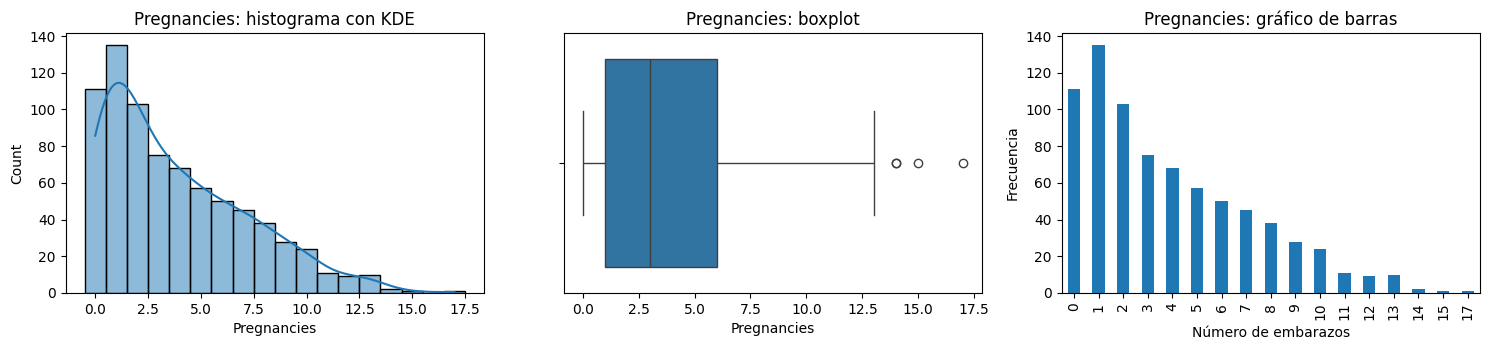

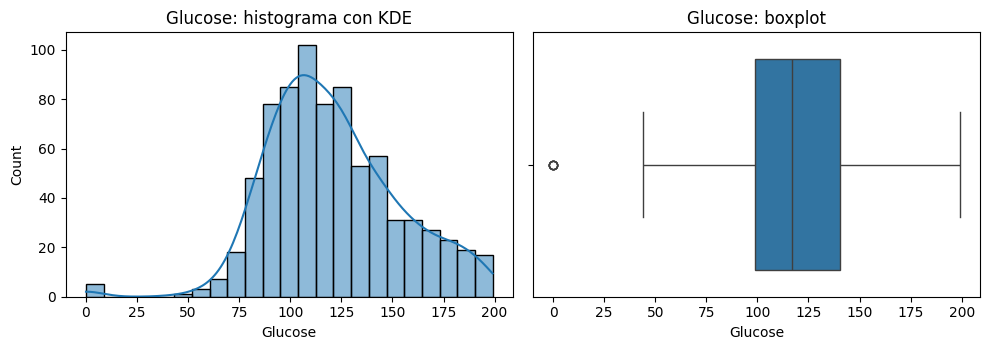

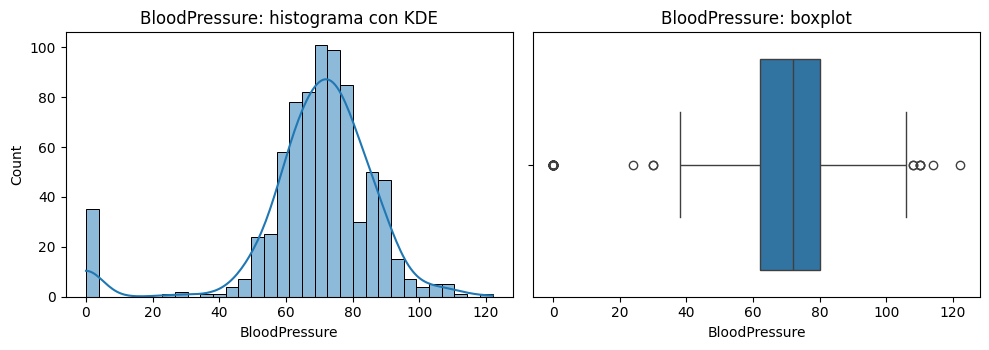

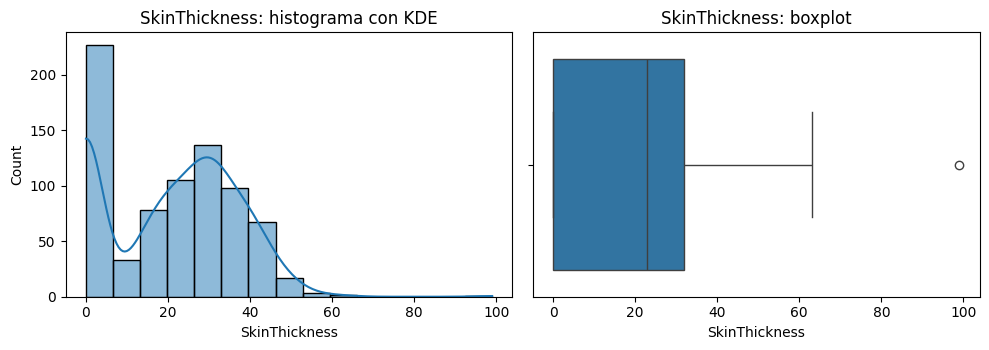

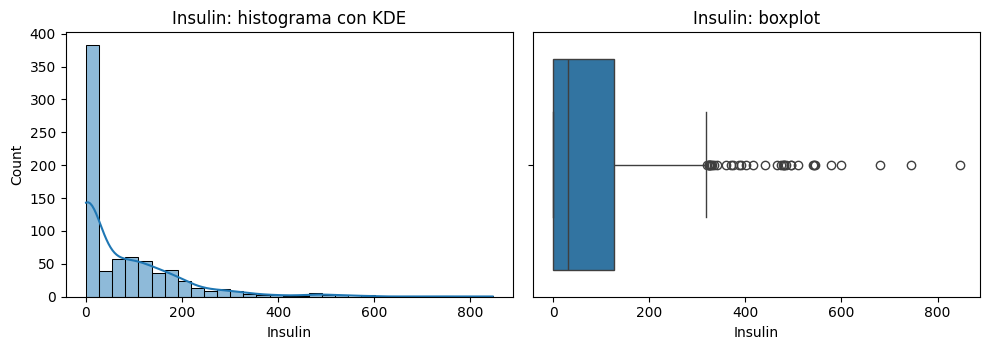

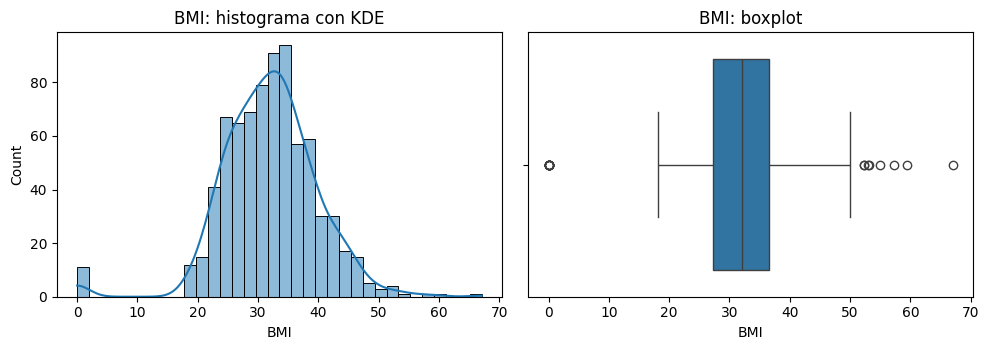

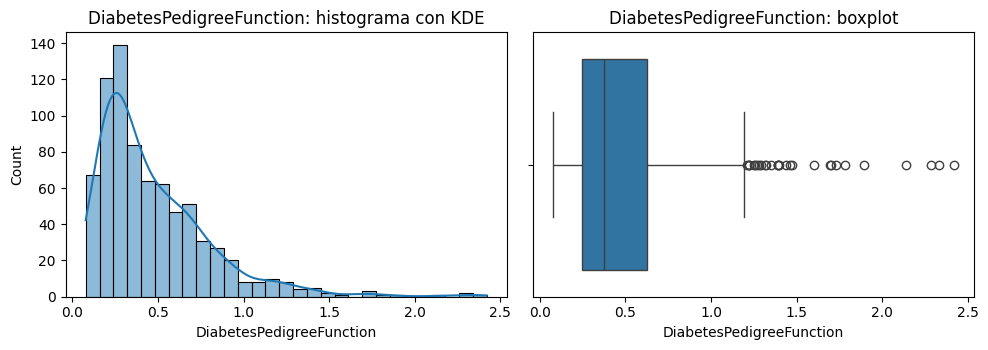

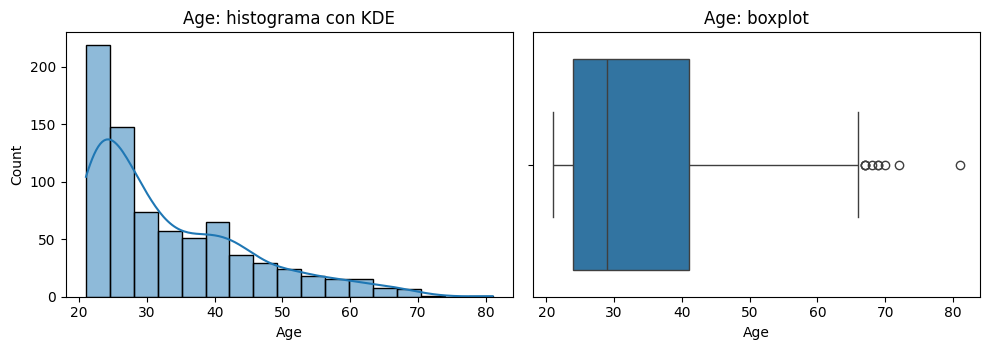

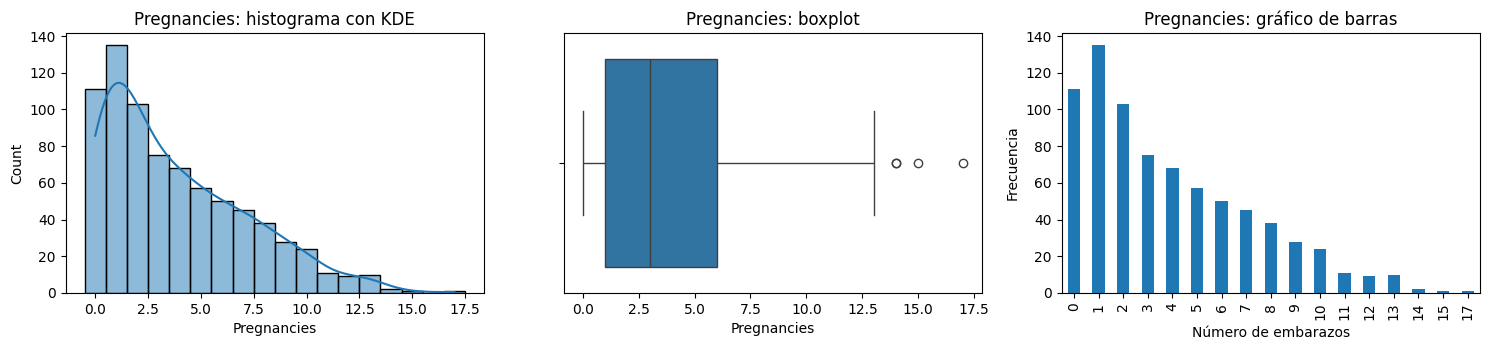

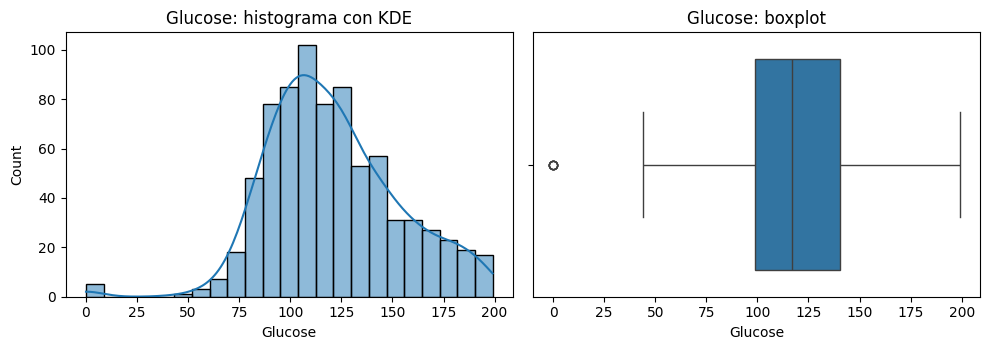

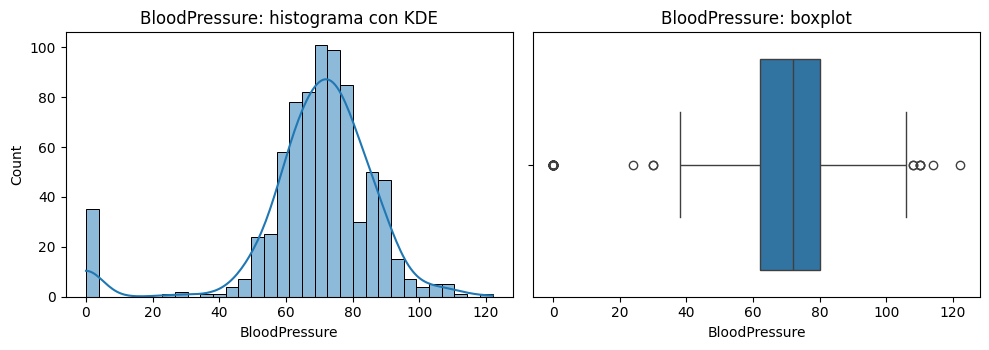

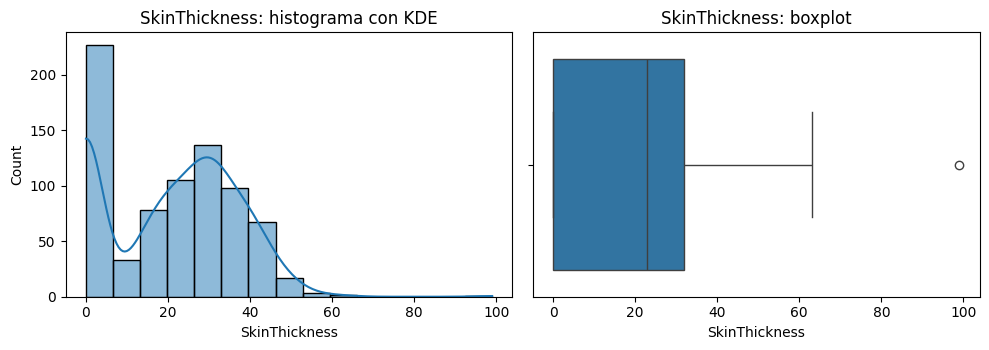

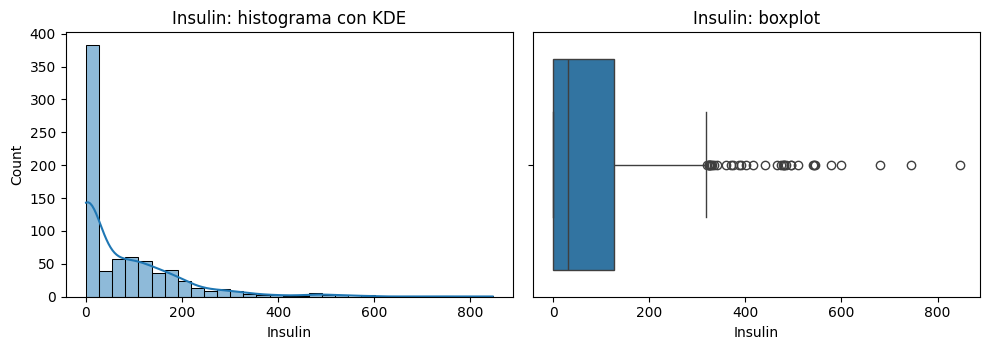

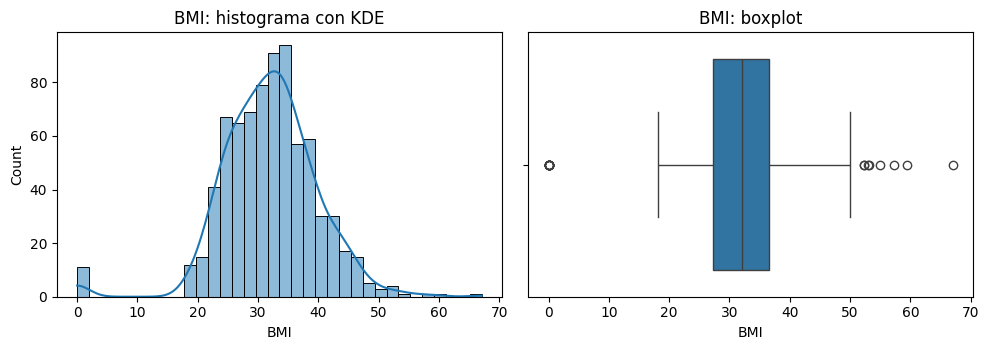

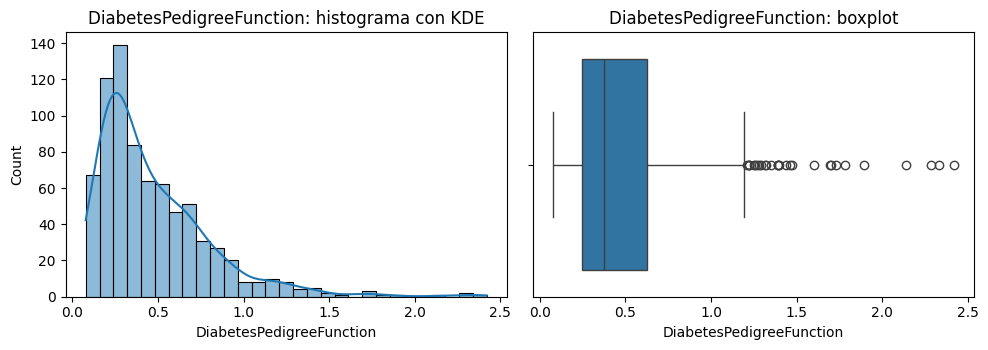

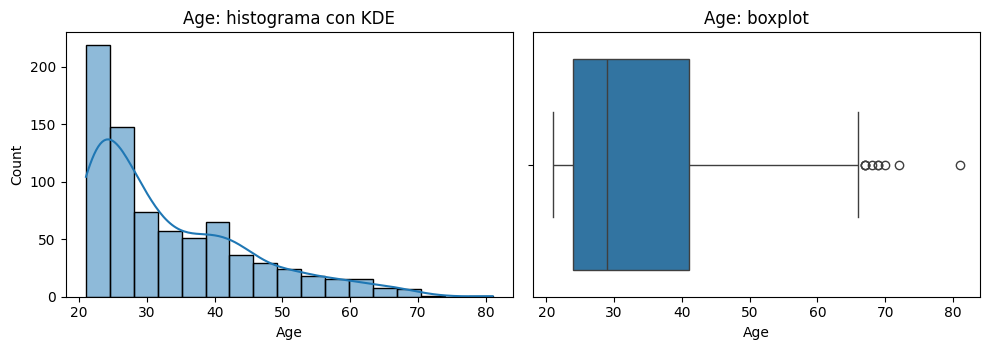

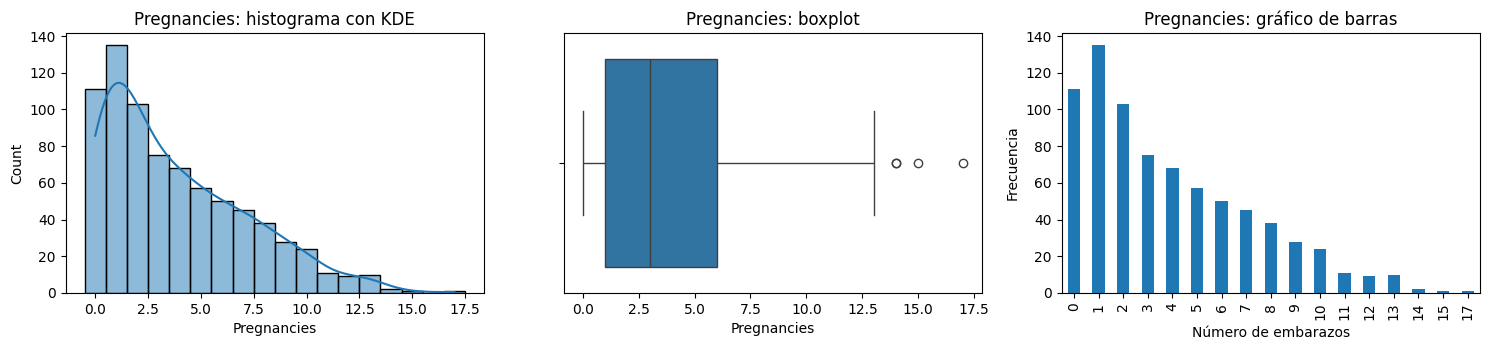

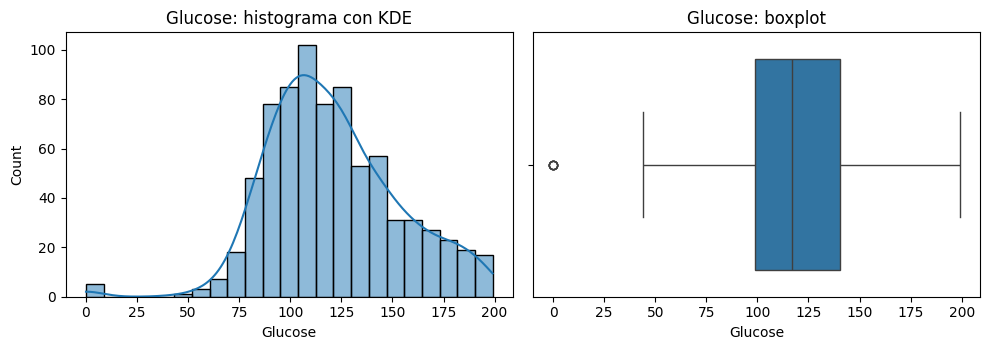

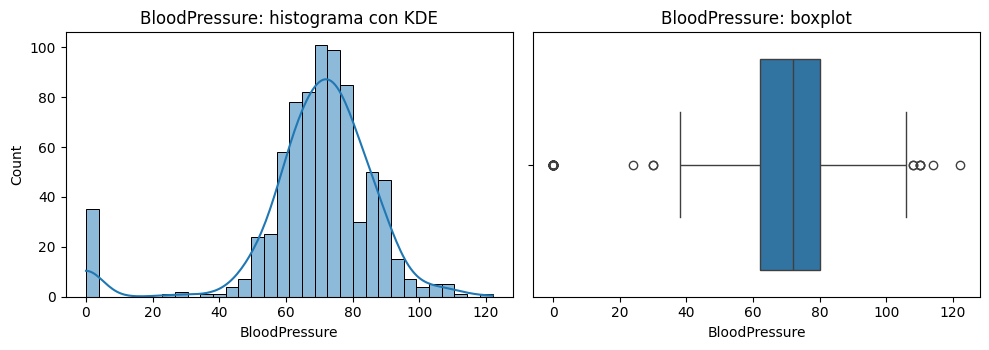

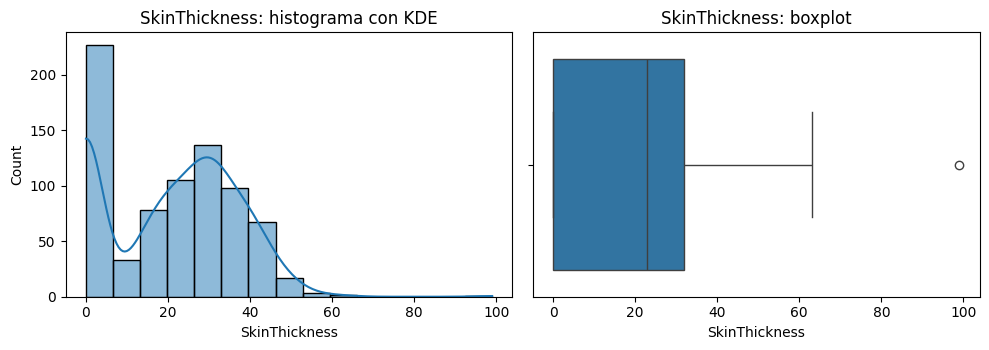

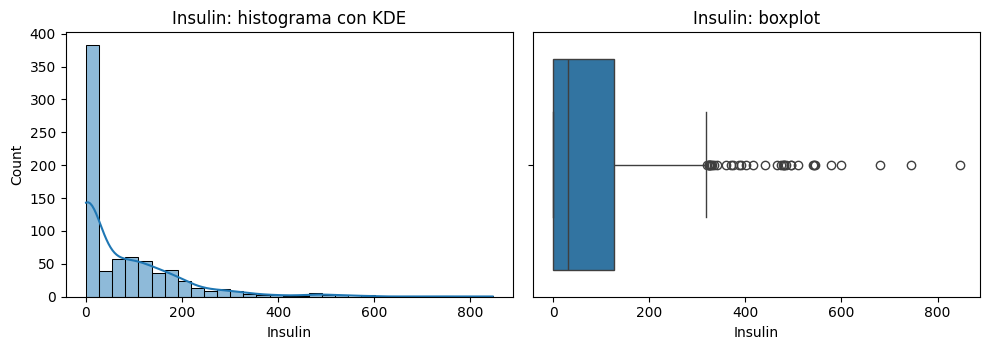

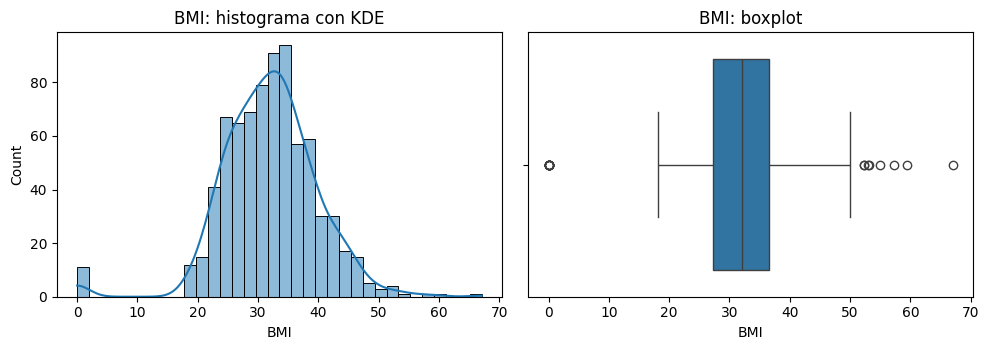

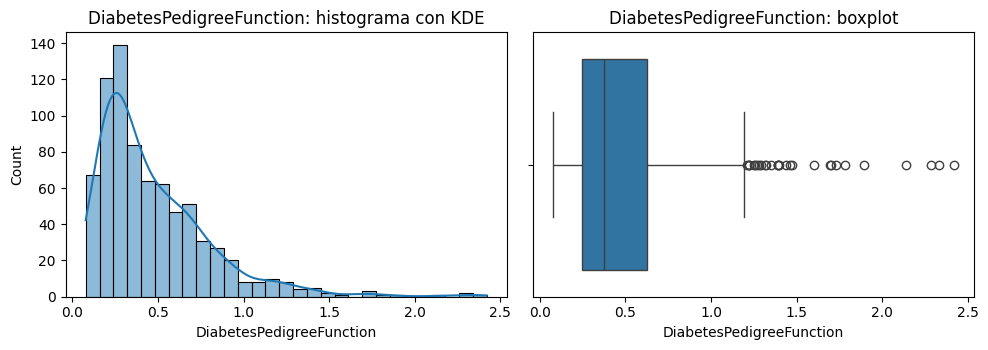

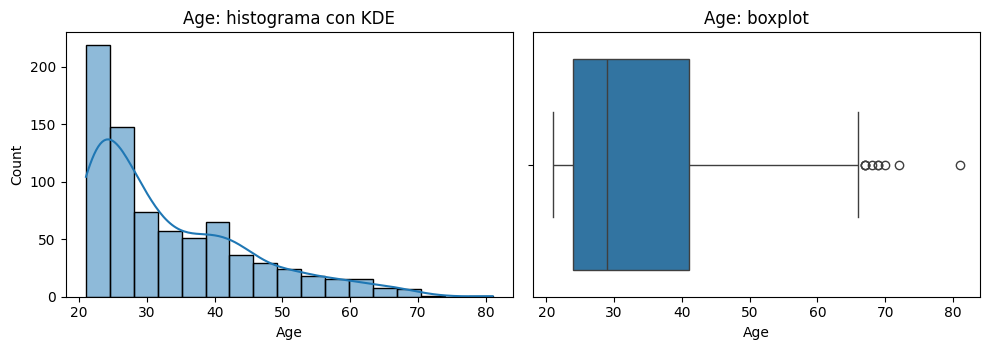

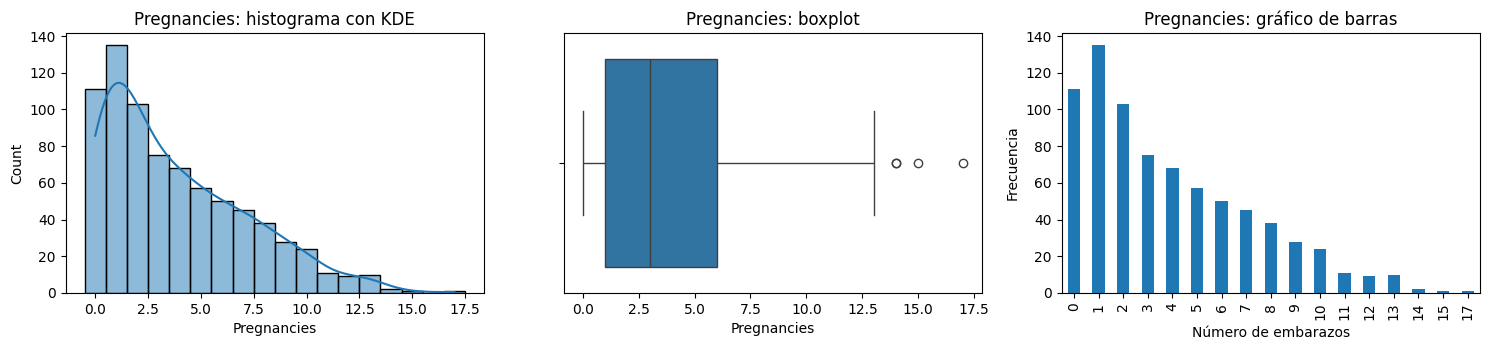

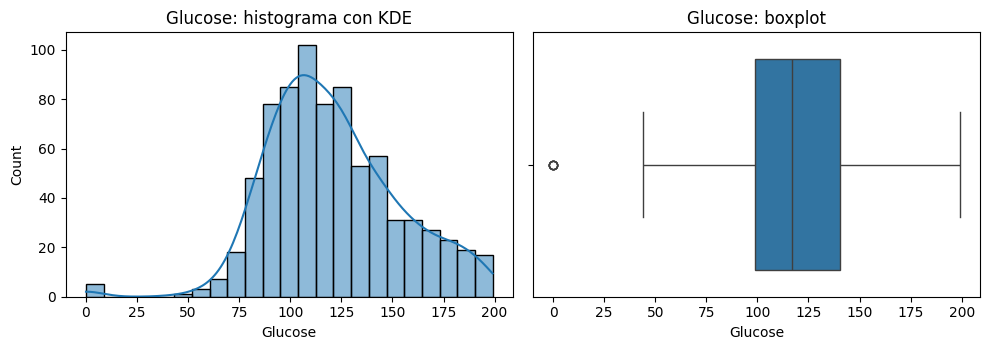

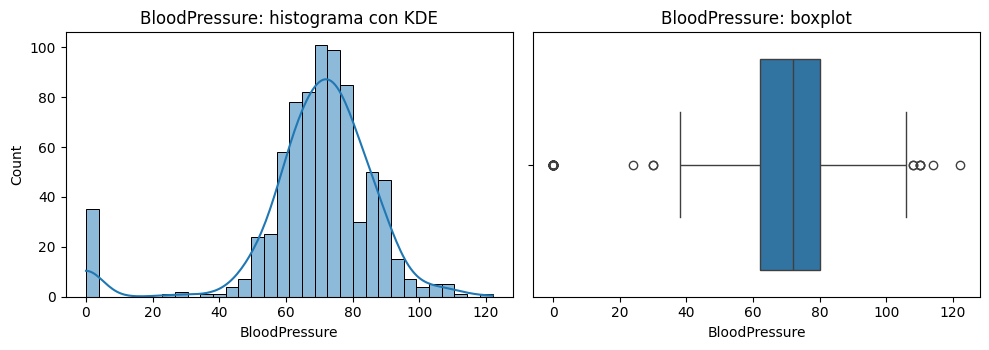

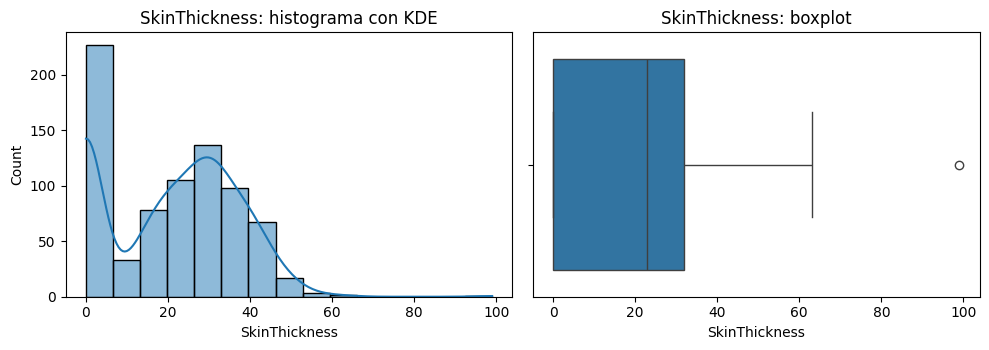

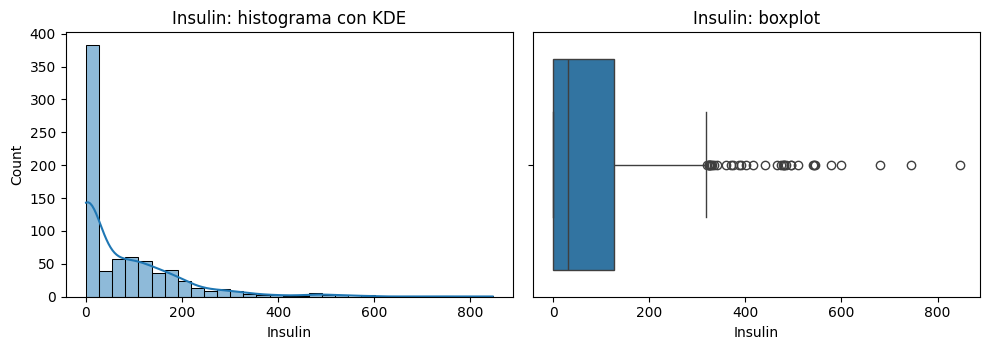

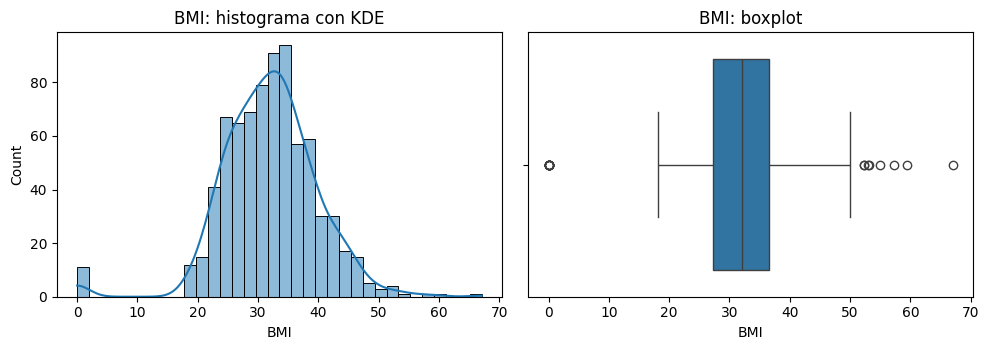

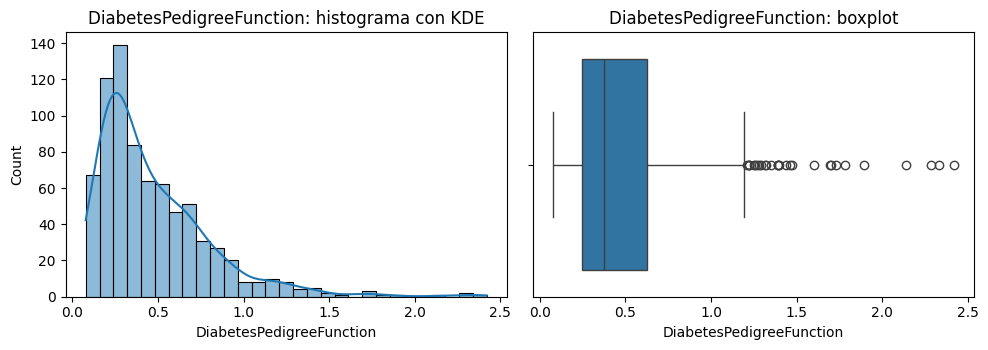

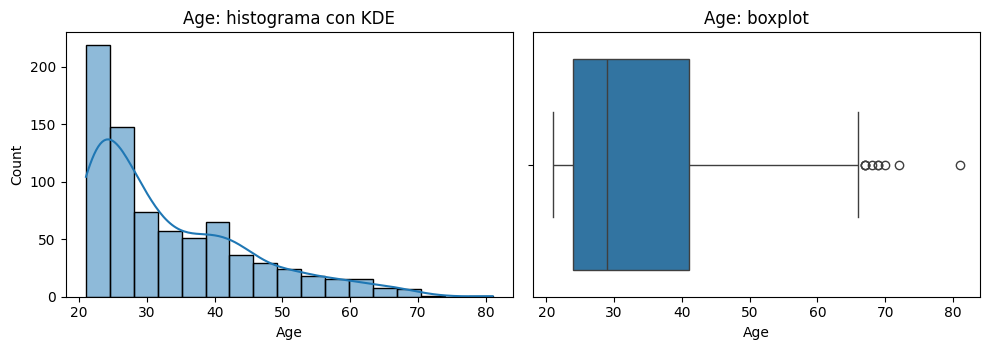

In [59]:
# Asegura que los gráficos se muestren dentro del notebook
%matplotlib inline

for var in variables_diab:
    es_preg = var == "Pregnancies"
    fig, ejes = plt.subplots(1, 3 if es_preg else 2, figsize=(15 if es_preg else 10, 3.6))

    sns.histplot(diabetes[var], kde=True, discrete=es_preg, ax=ejes[0])
    ejes[0].set_title(f"{var}: histograma con KDE")

    sns.boxplot(x=diabetes[var], ax=ejes[1])
    ejes[1].set_title(f"{var}: boxplot")

    if es_preg:
        diabetes[var].value_counts().sort_index().plot(kind="bar", ax=ejes[2])
        ejes[2].set_title("Pregnancies: gráfico de barras")
        ejes[2].set_xlabel("Número de embarazos")
        ejes[2].set_ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()
    plt.close(fig)  # libera la figura para no acumularlas en memoria


**Comentario (f).** Los gráficos permiten comprobar visualmente lo visto en las tablas: la barra en 0 de `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` (ceros imposibles), las colas largas a la derecha de `Insulin`, `DiabetesPedigreeFunction`, `Age` y `Pregnancies`, y los puntos fuera de los bigotes del boxplot, que corresponden a los atípicos de (b).

### Punto 2: faltantes disfrazados de cero
En varias variables clínicas un cero no es una medición real sino un dato faltante codificado como 0. Lo identificamos, lo reemplazamos por `NaN` en una copia del DataFrame y medimos cómo cambian las estadísticas.

#### 2.1 Conteo de ceros por variable
Contamos los ceros de cada variable y marcamos en cuáles un cero es biológicamente imposible.

In [60]:
# ¿Es biológicamente posible un valor 0 en cada variable? (criterio del analista)
cero_posible = {
    "Pregnancies": "Sí (puede no haber tenido embarazos)",
    "Glucose": "No (sin glucosa en sangre no hay vida)",
    "BloodPressure": "No (presión diastólica de 0 mm Hg es incompatible con la vida)",
    "SkinThickness": "No (el pliegue cutáneo siempre tiene un grosor medible)",
    "Insulin": "No (un nivel de insulina de 0 no es una medición real)",
    "BMI": "No (peso y talla positivos implican un IMC mayor que 0)",
    "DiabetesPedigreeFunction": "Sí (índice sin antecedentes, aunque no hay ceros)",
    "Age": "No (la edad mínima observada es 21; no hay ceros)",
}

tabla_ceros = pd.DataFrame({
    "ceros": (x == 0).sum(),
    "ceros_%": ((x == 0).mean() * 100).round(1),
    "¿cero posible?": pd.Series(cero_posible),
})
display(tabla_ceros)

# Variables donde un cero es biológicamente imposible y hay ceros en los datos
vars_cero_imposible = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Variables con ceros imposibles:", vars_cero_imposible)
print("Registros con al menos un cero imposible:", int((diabetes[vars_cero_imposible] == 0).any(axis=1).sum()), "de", len(diabetes))

,ceros,ceros_%,¿cero posible?
Pregnancies,111,14.5,Sí (puede no haber tenido embarazos)
Glucose,5,0.7,No (sin glucosa en sangre no hay vida)
BloodPressure,35,4.6,No (presión diastólica de 0 mm Hg es incompati...
SkinThickness,227,29.6,No (el pliegue cutáneo siempre tiene un grosor...
Insulin,374,48.7,No (un nivel de insulina de 0 no es una medici...
BMI,11,1.4,No (peso y talla positivos implican un IMC may...
DiabetesPedigreeFunction,0,0.0,"Sí (índice sin antecedentes, aunque no hay ceros)"
Age,0,0.0,No (la edad mínima observada es 21; no hay ceros)


Variables con ceros imposibles: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
Registros con al menos un cero imposible: 376 de 768


**Comentario (2.1).** Hay ceros en 6 de las 8 variables. Un cero es biológicamente imposible en `Glucose` (5), `BloodPressure` (35), `SkinThickness` (227), `Insulin` (374) y `BMI` (11). En `Pregnancies` hay 111 ceros que sí son válidos (mujeres sin embarazos), y `DiabetesPedigreeFunction` y `Age` no tienen ceros. Los ceros imposibles son especialmente frecuentes en `Insulin` (48,7 %) y `SkinThickness` (29,6 %), lo que indica que son registros que no se midieron.

En total, 376 de los 768 registros tienen al menos un cero imposible.

#### 2.2 Reemplazo de los ceros por NaN en una copia
Creamos `diabetes_nan` con los ceros imposibles convertidos a `NaN` y recalculamos media, mediana, sesgo y curtosis. El DataFrame original `diabetes` queda intacto.

In [61]:
# Copia del DataFrame: el original (diabetes) no se modifica
diabetes_nan = diabetes.copy()
diabetes_nan[vars_cero_imposible] = diabetes_nan[vars_cero_imposible].replace(0, np.nan)

# Verificación: nulos en la copia y ceros que siguen en el original
verificacion = pd.DataFrame({
    "ceros_en_original": (diabetes[vars_cero_imposible] == 0).sum(),
    "nulos_en_copia": diabetes_nan[vars_cero_imposible].isna().sum(),
    "valores_válidos_en_copia": diabetes_nan[vars_cero_imposible].count(),
})
display(verificacion)

# Medidas recalculadas sobre la copia (pandas ignora los NaN)
despues = pd.DataFrame({
    "media": diabetes_nan[vars_cero_imposible].mean(),
    "mediana": diabetes_nan[vars_cero_imposible].median(),
    "sesgo": diabetes_nan[vars_cero_imposible].skew(),
    "curtosis": diabetes_nan[vars_cero_imposible].kurt(),
})
despues.round(3)

,ceros_en_original,nulos_en_copia,valores_válidos_en_copia
Glucose,5,5,763
BloodPressure,35,35,733
SkinThickness,227,227,541
Insulin,374,374,394
BMI,11,11,757


,media,mediana,sesgo,curtosis
Glucose,121.687,117.0,0.531,-0.277
BloodPressure,72.405,72.0,0.134,0.911
SkinThickness,29.153,29.0,0.691,2.935
Insulin,155.548,125.0,2.166,6.371
BMI,32.457,32.3,0.594,0.863


**Comentario (2.2).** Los nulos de la copia coinciden con los ceros del original (5, 35, 227, 374 y 11), por lo que el reemplazo fue exacto. Los valores válidos que quedan son 763 en `Glucose`, 733 en `BloodPressure`, 541 en `SkinThickness`, 394 en `Insulin` y 757 en `BMI`. Las estadísticas de la tabla se calculan solo con esos valores, porque pandas ignora los `NaN`.

#### 2.3 Tabla "antes y después" y análisis del cambio

In [62]:
antes = pd.DataFrame({
    "media": diabetes[vars_cero_imposible].mean(),
    "mediana": diabetes[vars_cero_imposible].median(),
    "sesgo": diabetes[vars_cero_imposible].skew(),
    "curtosis": diabetes[vars_cero_imposible].kurt(),
})

# Tabla "antes y después" (antes = con ceros; después = ceros reemplazados por NaN)
antes_despues = pd.concat({"antes": antes, "después": despues}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
antes_despues = antes_despues[["media", "mediana", "sesgo", "curtosis"]]
display(antes_despues.round(3))

# Tamaño del cambio: relativo (%) en media y mediana, absoluto en sesgo y curtosis
cambios = pd.DataFrame({
    "media_cambio_%": ((despues["media"] - antes["media"]) / antes["media"] * 100).round(1),
    "mediana_cambio_%": ((despues["mediana"] - antes["mediana"]) / antes["mediana"] * 100).round(1),
    "sesgo_cambio": (despues["sesgo"] - antes["sesgo"]).round(3),
    "curtosis_cambio": (despues["curtosis"] - antes["curtosis"]).round(3),
})
display(cambios)

# ¿Qué pasa si se reporta la media original de Insulin?
media_original = diabetes["Insulin"].mean()
media_valida = diabetes_nan["Insulin"].mean()
print(f"Media de Insulin original (con ceros): {media_original:.1f}")
print(f"Media de Insulin con los ceros como NaN: {media_valida:.1f}")
print(f"La media original subestima en {(1 - media_original / media_valida) * 100:.1f} % (equivale a {media_original / media_valida:.2f} veces la media válida)")

media          mediana          sesgo         curtosis  \
                 antes  después   antes después  antes después    antes   
Glucose        120.895  121.687   117.0   117.0  0.174   0.531    0.641   
BloodPressure   69.105   72.405    72.0    72.0 -1.844   0.134    5.180   
SkinThickness   20.536   29.153    23.0    29.0  0.109   0.691   -0.520   
Insulin         79.799  155.548    30.5   125.0  2.272   2.166    7.214   
BMI             31.993   32.457    32.0    32.3 -0.429   0.594    3.290   

                       
              después  
Glucose        -0.277  
BloodPressure   0.911  
SkinThickness   2.935  
Insulin         6.371  
BMI             0.863

,media_cambio_%,mediana_cambio_%,sesgo_cambio,curtosis_cambio
Glucose,0.7,0.0,0.357,-0.918
BloodPressure,4.8,0.0,1.978,-4.269
SkinThickness,42.0,26.1,0.581,3.456
Insulin,94.9,309.8,-0.106,-0.844
BMI,1.5,0.9,1.023,-2.427


Media de Insulin original (con ceros): 79.8
Media de Insulin con los ceros como NaN: 155.5
La media original subestima en 48.7 % (equivale a 0.51 veces la media válida)


**Comentario (2.3).**
- **Qué medida cambió más.** En media y mediana, el mayor cambio relativo está en la **mediana de `Insulin`**: pasa de 30,5 a 125,0 (+309,8 %); su media pasa de 79,8 a 155,5 (+94,9 %). En sesgo y curtosis, el mayor cambio absoluto está en `BloodPressure` (curtosis 5,18 → 0,91; sesgo -1,84 → 0,13) y en `SkinThickness` (curtosis -0,52 → 2,94).
- **Por qué cambió tanto la mediana de `Insulin`.** El 48,7 % de sus valores eran ceros, casi la mitad. Con tantos ceros al inicio de la distribución ordenada, la mediana quedaba atrapada en la zona baja (30,5). Al quitarlos, la mediana pasa a ser el valor central de las mediciones reales.
- **Por qué cambiaron el sesgo y la curtosis de `BloodPressure`.** Sus 35 ceros eran valores extremos muy lejos del resto (entre 24 y 122 mm Hg en los datos válidos). Eso producía una cola izquierda larga, el sesgo negativo y colas pesadas (curtosis 5,18). Sin ellos, la distribución es casi simétrica.
- **Cambios pequeños:** en `Glucose` y `BMI` las medias cambian poco (+0,7 % y +1,5 %) porque tienen pocos ceros (0,7 % y 1,4 %). En esas variables sí cambia el sesgo, que pasa de aproximadamente simétrico a positivo moderado, y la curtosis.
- **Si alguien reportara la media original de `Insulin` (79,8):** subestimaría el nivel real de insulina medida en casi la mitad (la media válida es 155,5; la original equivale a 0,51 veces). Ese número mezcla mediciones con registros que no se midieron, y podría llevar a conclusiones clínicas erróneas.

> **Precaución:** los nuevos valores son estadísticas de los registros que sí tienen medición. Si las mediciones faltantes no son aleatorias (por ejemplo, si no se midió insulina a ciertos pacientes), esas estadísticas pueden no representar a todos los pacientes.

### Punto 3: balance de la variable `Outcome`
Revisamos cuántos registros hay en cada clase de `Outcome`, si la variable está balanceada y cómo se comparan `Glucose` y `BMI` entre las dos clases.

#### 3.1 Frecuencia, porcentaje y gráfico de barras

,frecuencia,porcentaje_%
Outcome,,
0,500,65.1
1,268,34.9


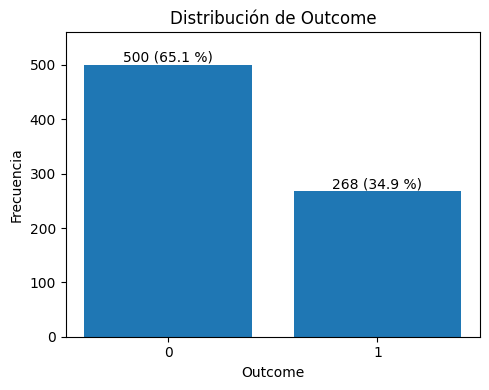

In [63]:
# Asegura que el gráfico se muestre dentro del notebook
%matplotlib inline

frecuencia = diabetes["Outcome"].value_counts().sort_index()
tabla_outcome = pd.DataFrame({
    "frecuencia": frecuencia,
    "porcentaje_%": (frecuencia / len(diabetes) * 100).round(2),
})
display(tabla_outcome)

# Gráfico de barras con la frecuencia y el porcentaje sobre cada barra
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(frecuencia.index.astype(str), frecuencia.values)
for barra, n, pct in zip(barras, tabla_outcome["frecuencia"], tabla_outcome["porcentaje_%"]):
    ax.text(barra.get_x() + barra.get_width() / 2, n, f"{n} ({pct:.1f} %)", ha="center", va="bottom")
ax.set_title("Distribución de Outcome")
ax.set_xlabel("Outcome")
ax.set_ylabel("Frecuencia")
ax.set_ylim(0, frecuencia.max() * 1.12)
plt.tight_layout()
plt.show()
plt.close(fig)

**Comentario (3.1).** `Outcome` tiene dos clases: 0 (500 registros, 65,10 %) y 1 (268 registros, 34,90 %). Por convención de este dataset, 1 indica un resultado positivo de diabetes (la descripción de `Outcome` no está en los archivos, así que esta lectura es un supuesto).

#### 3.2 ¿Es una variable balanceada?
Usamos como criterio que una variable binaria está balanceada si cada clase está entre el 40 % y el 60 %.

In [64]:
pct = tabla_outcome["porcentaje_%"]
razon_desbalance = frecuencia.max() / frecuencia.min()

print(f"Clase mayoritaria: {pct.max():.1f} % | clase minoritaria: {pct.min():.1f} %")
print(f"Razón mayoritaria/minoritaria: {razon_desbalance:.2f} a 1")
print(f"Exactitud de un modelo que siempre predice la clase mayoritaria: {pct.max():.1f} %")

# Criterio: balanceada si cada clase está entre 40 % y 60 %
balanceada = bool(pct.between(40, 60).all())
print("¿Balanceada (cada clase entre 40 % y 60 %)?:", "Sí" if balanceada else "No")

Clase mayoritaria: 65.1 % | clase minoritaria: 34.9 %
Razón mayoritaria/minoritaria: 1.87 a 1
Exactitud de un modelo que siempre predice la clase mayoritaria: 65.1 %
¿Balanceada (cada clase entre 40 % y 60 %)?: No


**Comentario (3.2).** **No está balanceada, pero el desbalance es moderado.** La clase 0 concentra el 65,1 % y la clase 1 el 34,9 %: hay 1,87 registros de la clase 0 por cada uno de la clase 1, y la clase minoritaria queda por debajo del 40 %. No es un desbalance extremo, porque la clase minoritaria tiene más de un tercio de los registros.

**Implicaciones:** un modelo que siempre predijera 0 acertaría el 65,1 % de las veces sin aprender nada, por lo que la exactitud (*accuracy*) sola engaña. Para modelar conviene usar métricas como recall, precisión y F1, dividir los datos de forma estratificada por `Outcome` y, si hace falta, ponderar las clases.

#### 3.3 Mediana de `Glucose` y `BMI` por clase de `Outcome`
Se calcula sobre la copia con los ceros imposibles como `NaN` (punto 2). También se muestran Q1, Q3 y el número de valores válidos de cada grupo.

In [65]:
variables_comparar = ["Glucose", "BMI"]

# Se usa la copia con los ceros imposibles como NaN (punto 2), para no sesgar las medianas
por_clase = diabetes_nan.groupby("Outcome")[variables_comparar]
comparacion = pd.concat({
    "mediana": por_clase.median(),
    "Q1": por_clase.quantile(0.25),
    "Q3": por_clase.quantile(0.75),
    "n_válidos": por_clase.count(),
}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(comparacion.round(2))

# Diferencia de medianas entre clases (Outcome 1 menos Outcome 0)
medianas = por_clase.median()
diferencia = pd.DataFrame({
    "mediana_Outcome_0": medianas.loc[0],
    "mediana_Outcome_1": medianas.loc[1],
    "diferencia": medianas.loc[1] - medianas.loc[0],
    "diferencia_%": ((medianas.loc[1] - medianas.loc[0]) / medianas.loc[0] * 100).round(1),
})
diferencia.round(2)

BMI                        Glucose                        
        mediana    Q1     Q3 n_válidos mediana     Q1     Q3 n_válidos
Outcome                                                               
0          30.1  25.6  35.30       491   107.0   93.0  125.0       497
1          34.3  30.9  38.92       266   140.0  119.0  167.0       266

,mediana_Outcome_0,mediana_Outcome_1,diferencia,diferencia_%
Glucose,107.0,140.0,33.0,30.8
BMI,30.1,34.3,4.2,14.0


**Comentario (3.3).** Las dos medianas son mayores en la clase 1:
- **`Glucose`:** 140 en la clase 1 frente a 107 en la clase 0 (+33; +30,8 %).
- **`BMI`:** 34,3 frente a 30,1 (+4,2; +14,0 %).

**Qué sugiere:** que los registros con `Outcome = 1` tienden a tener más glucosa y mayor índice de masa corporal, por lo que ambas variables parecen asociadas con `Outcome` y podrían ser buenas variables predictoras. La diferencia es más marcada en `Glucose`: su Q1 en la clase 1 (119) está cerca del Q3 de la clase 0 (125), es decir, las distribuciones se separan bastante. En `BMI` el solapamiento es mayor (Q1 de la clase 1 = 30,9; Q3 de la clase 0 = 35,3).

**Precauciones:** una diferencia de medianas describe una asociación, no demuestra causalidad. Tampoco es una prueba estadística: para saber si la diferencia es significativa haría falta una prueba de hipótesis. Y las clases tienen tamaños distintos (500 y 268), aunque la mediana es robusta a eso. Calculada con los datos originales (con los ceros), la mediana de `Glucose` es la misma (107 y 140), mientras que la de `BMI` cambia muy poco (30,05 y 34,25).